In [54]:
from pathlib import Path

DATA_DIR = Path('/kaggle/input/datasets/saamiyah26/refit-clean')

print(list(DATA_DIR.glob("*.csv")))

[PosixPath('/kaggle/input/datasets/saamiyah26/refit-clean/CLEAN_House1.csv'), PosixPath('/kaggle/input/datasets/saamiyah26/refit-clean/CLEAN_House10.csv'), PosixPath('/kaggle/input/datasets/saamiyah26/refit-clean/CLEAN_House11.csv'), PosixPath('/kaggle/input/datasets/saamiyah26/refit-clean/CLEAN_House12.csv'), PosixPath('/kaggle/input/datasets/saamiyah26/refit-clean/CLEAN_House13.csv'), PosixPath('/kaggle/input/datasets/saamiyah26/refit-clean/CLEAN_House15.csv'), PosixPath('/kaggle/input/datasets/saamiyah26/refit-clean/CLEAN_House16.csv'), PosixPath('/kaggle/input/datasets/saamiyah26/refit-clean/CLEAN_House17.csv'), PosixPath('/kaggle/input/datasets/saamiyah26/refit-clean/CLEAN_House18.csv'), PosixPath('/kaggle/input/datasets/saamiyah26/refit-clean/CLEAN_House19.csv'), PosixPath('/kaggle/input/datasets/saamiyah26/refit-clean/CLEAN_House2.csv'), PosixPath('/kaggle/input/datasets/saamiyah26/refit-clean/CLEAN_House20.csv'), PosixPath('/kaggle/input/datasets/saamiyah26/refit-clean/CLEAN_Ho

In [55]:
df=pd.read_csv('/kaggle/input/datasets/saamiyah26/refit-clean/CLEAN_House1.csv')

In [56]:
df.head()

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9,Issues
0,2013-10-09 13:06:17,1381323977,523,74,0,69,0,0,0,0,0,1,0
1,2013-10-09 13:06:31,1381323991,526,75,0,69,0,0,0,0,0,1,0
2,2013-10-09 13:06:46,1381324006,540,74,0,68,0,0,0,0,0,1,0
3,2013-10-09 13:07:01,1381324021,532,74,0,68,0,0,0,0,0,1,0
4,2013-10-09 13:07:15,1381324035,540,74,0,69,0,0,0,0,0,1,0


In [57]:

# ============================================================
# EXPERIMENT 3: CNN-BASED SEQ2POINT NILM
# Kaggle-compatible configuration
# Independent implementation: does not overwrite earlier work
# ============================================================

import os
import gc
import json
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from numpy.lib.stride_tricks import sliding_window_view

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    f1_score,
    precision_score,
    recall_score
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. REPRODUCIBILITY
# ------------------------------------------------------------

CNN_SEED = 42

random.seed(CNN_SEED)
np.random.seed(CNN_SEED)
tf.keras.utils.set_random_seed(CNN_SEED)


# ------------------------------------------------------------
# 2. KAGGLE DATASET PATH
# ------------------------------------------------------------

CNN_DATA_DIR = Path("/kaggle/input/datasets/saamiyah26/refit-clean")

if not CNN_DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset directory not found: {CNN_DATA_DIR}"
    )

if not (CNN_DATA_DIR / "CLEAN_House3.csv").exists():
    raise FileNotFoundError(
        f"CLEAN_House3.csv not found inside {CNN_DATA_DIR}"
    )

print("Dataset successfully located:", CNN_DATA_DIR)
print("Available CSV files:", len(list(CNN_DATA_DIR.glob("*.csv"))))


# ------------------------------------------------------------
# 3. OUTPUT DIRECTORY
# ------------------------------------------------------------

# Kaggle input is READ-ONLY.
# All experiment outputs must go into /kaggle/working/.

CNN_OUTPUT_DIR = Path("/kaggle/working/cnn_seq2point_experiment")
CNN_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 4. VERIFY REQUIRED HOUSEHOLD FILES
# ------------------------------------------------------------

CNN_APP_INDEX = {
    3: 6,
    7: 5,
    8: 4,
    10: 5,
    13: 3,
    16: 5
}

required_houses = [3, 7, 8, 10, 13, 16]

missing_files = [
    house for house in required_houses
    if not (CNN_DATA_DIR / f"CLEAN_House{house}.csv").exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing household CSV files: {missing_files}"
    )

print("All required household files are available.")

# ------------------------------------------------------------
# 5. SEQ2POINT CONFIGURATION
# ------------------------------------------------------------

CNN_WINDOW_SIZE = 121
CNN_CENTER_INDEX = CNN_WINDOW_SIZE // 2

# Household-level split
CNN_TRAIN_HOUSES = [3, 7, 8, 10]
CNN_VAL_HOUSES = [13]
CNN_TEST_HOUSES = [16]

# Window generation
CNN_TRAIN_STRIDE = 5
CNN_EVAL_STRIDE = 5

# Maximum samples per household
CNN_MAX_TRAIN_PER_HOUSE = 60000
CNN_MAX_VAL_PER_HOUSE = 25000
CNN_MAX_TEST_PER_HOUSE = None

# Power normalization
CNN_AGGREGATE_SCALE = 3000.0
CNN_TARGET_SCALE = 2000.0

# Activity threshold
CNN_ACTIVE_THRESHOLD = 50.0

# ------------------------------------------------------------
# 6. TRAINING CONFIGURATION
# ------------------------------------------------------------

CNN_BATCH_SIZE = 256
CNN_EPOCHS = 50
CNN_LEARNING_RATE = 0.001

# ------------------------------------------------------------
# 7. ENVIRONMENT CHECK
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("CNN SEQ2POINT CONFIGURATION LOADED")
print("=" * 55)

print("Dataset:", CNN_DATA_DIR)
print("Output:", CNN_OUTPUT_DIR)

print("\nTensorFlow version:", tf.__version__)

gpu_devices = tf.config.list_physical_devices("GPU")
print("GPU devices:", gpu_devices)

if gpu_devices:
    print("GPU acceleration is available.")
else:
    print("No GPU detected. Enable GPU in Kaggle Notebook Settings.")

print("\nHouseholds:")
print("Training:", CNN_TRAIN_HOUSES)
print("Validation:", CNN_VAL_HOUSES)
print("Testing:", CNN_TEST_HOUSES)

print("\nRequired CSV files:")
for house in required_houses:
    file_path = CNN_DATA_DIR / f"CLEAN_House{house}.csv"
    print(f"House {house}: {file_path.stat().st_size / (1024**2):.1f} MB")

print("\nConfiguration ready. You can run the next cell.")


Dataset successfully located: /kaggle/input/datasets/saamiyah26/refit-clean
Available CSV files: 20
All required household files are available.

CNN SEQ2POINT CONFIGURATION LOADED
Dataset: /kaggle/input/datasets/saamiyah26/refit-clean
Output: /kaggle/working/cnn_seq2point_experiment

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
GPU acceleration is available.

Households:
Training: [3, 7, 8, 10]
Validation: [13]
Testing: [16]

Required CSV files:
House 3: 388.4 MB
House 7: 371.0 MB
House 8: 339.0 MB
House 10: 380.3 MB
House 13: 263.7 MB
House 16: 318.5 MB

Configuration ready. You can run the next cell.


In [58]:
# ============================================================
# CNN DATA LOADING AND PREPROCESSING
# ============================================================

def cnn_load_house_data(house_id):

    appliance_index = CNN_APP_INDEX[house_id]
    appliance_column = f"Appliance{appliance_index}"

    file_path = (
        CNN_DATA_DIR / f"CLEAN_House{house_id}.csv"
    )

    if not file_path.exists():
        raise FileNotFoundError(
            f"Missing dataset file: {file_path}"
        )

    df = pd.read_csv(
        file_path,
        parse_dates=["Time"]
    )

    required_columns = [
        "Time",
        "Aggregate",
        appliance_column,
        "Issues"
    ]

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"House {house_id}: missing {missing_columns}"
        )

    original_rows = len(df)

    # Keep rows without reported issues.
    df = df[df["Issues"] == 0].copy()

    # Convert measurements to numeric.
    df["Aggregate"] = pd.to_numeric(
        df["Aggregate"],
        errors="coerce"
    )

    df[appliance_column] = pd.to_numeric(
        df[appliance_column],
        errors="coerce"
    )

    # Remove invalid timestamps.
    df = df.dropna(subset=["Time"])

    # Average duplicate timestamps.
    df = (
        df.sort_values("Time")
        .groupby("Time", as_index=False)[
            ["Aggregate", appliance_column]
        ]
        .mean()
    )

    # Resample to one-minute intervals.
    # Missing minutes remain NaN.
    minute_df = (
        df.set_index("Time")
        .resample("1min")
        .mean()
        .reset_index()
    )

    minute_df = minute_df.rename(
        columns={
            "Time": "timestamp",
            "Aggregate": "aggregate",
            appliance_column: "target"
        }
    )

    # Negative appliance measurements are treated as zero.
    # Aggregate measurements are not modified.
    negative_targets = int(
        (minute_df["target"].dropna() < 0).sum()
    )

    minute_df.loc[
        minute_df["target"] < 0,
        "target"
    ] = 0

    valid_mask = (
        minute_df["aggregate"].notna()
        & minute_df["target"].notna()
    )

    stats = {
        "house": house_id,
        "original_rows": original_rows,
        "minute_rows": len(minute_df),
        "valid_minutes": int(valid_mask.sum()),
        "missing_minutes": int((~valid_mask).sum()),
        "valid_coverage_percent": (
            100 * valid_mask.mean()
            if len(minute_df) else 0
        ),
        "negative_target_readings": negative_targets
    }

    return minute_df, stats

In [59]:
# ============================================================
# CNN SEQ2POINT WINDOW GENERATION
# ============================================================

def cnn_make_windows(
    df,
    stride=5,
    max_samples=60000
):

    aggregate = df["aggregate"].to_numpy(
        dtype=np.float32
    )

    target = df["target"].to_numpy(
        dtype=np.float32
    )

    timestamps = df["timestamp"].to_numpy()

    valid = (
        np.isfinite(aggregate)
        & np.isfinite(target)
    )

    valid_indices = np.where(valid)[0]

    if len(valid_indices) == 0:

        return (
            np.empty((0, CNN_WINDOW_SIZE), dtype=np.float32),
            np.empty(0, dtype=np.float32),
            np.empty(0, dtype="datetime64[ns]")
        )

    # Separate continuous valid segments.
    split_positions = np.where(
        np.diff(valid_indices) > 1
    )[0] + 1

    segments = np.split(
        valid_indices,
        split_positions
    )

    X_parts = []
    y_parts = []
    timestamp_parts = []

    for segment in segments:

        if len(segment) < CNN_WINDOW_SIZE:
            continue

        segment_aggregate = aggregate[segment]

        all_windows = sliding_window_view(
            segment_aggregate,
            CNN_WINDOW_SIZE
        )

        # Select windows using the configured stride.
        starts = np.arange(
            0,
            len(all_windows),
            stride
        )

        X_segment = all_windows[starts]

        center_indices = (
            segment[starts + CNN_CENTER_INDEX]
        )

        y_segment = target[center_indices]

        timestamp_segment = timestamps[center_indices]

        X_parts.append(X_segment)
        y_parts.append(y_segment)
        timestamp_parts.append(timestamp_segment)

    if not X_parts:

        return (
            np.empty((0, CNN_WINDOW_SIZE), dtype=np.float32),
            np.empty(0, dtype=np.float32),
            np.empty(0, dtype="datetime64[ns]")
        )

    X = np.concatenate(X_parts).astype(np.float32)
    y = np.concatenate(y_parts).astype(np.float32)

    selected_timestamps = np.concatenate(
        timestamp_parts
    )

    # Preserve all test windows in chronological order.
    # Do not downsample the test set.

    if max_samples is not None and len(X) > max_samples:
        indices = np.linspace( 0, len(X) - 1,max_samples,dtype=int)

        X = X[indices]
        y = y[indices]
        timestamps = timestamps[indices]

    return X, y, selected_timestamps

In [60]:
# ============================================================
# BUILD CNN DATASETS
# ============================================================

def cnn_build_dataset(
    houses,
    stride,
    max_samples_per_house
):

    X_parts = []
    y_parts = []
    timestamp_parts = []
    quality_stats = []

    for house_id in houses:

        print(f"\nProcessing House {house_id}...")

        df, stats = cnn_load_house_data(house_id)

        X, y, timestamps = cnn_make_windows(
            df,
            stride=stride,
            max_samples=max_samples_per_house
        )

        print(f"Generated windows: {len(X):,}")

        print(
            f"Valid coverage: "
            f"{stats['valid_coverage_percent']:.2f}%"
        )

        if len(X) == 0:
            raise ValueError(
                f"No valid windows for House {house_id}"
            )

        X_parts.append(X)
        y_parts.append(y)
        timestamp_parts.append(timestamps)

        quality_stats.append(stats)

        del df
        gc.collect()

    X = np.concatenate(X_parts, axis=0)
    y = np.concatenate(y_parts, axis=0)
    timestamps = np.concatenate(timestamp_parts)

    return X, y, timestamps, quality_stats


cnn_start = time.time()

X_train_cnn, y_train_cnn, train_times_cnn, train_quality_cnn = (
    cnn_build_dataset(
        CNN_TRAIN_HOUSES,
        CNN_TRAIN_STRIDE,
        CNN_MAX_TRAIN_PER_HOUSE
    )
)

X_val_cnn, y_val_cnn, val_times_cnn, val_quality_cnn = (
    cnn_build_dataset(
        CNN_VAL_HOUSES,
        CNN_EVAL_STRIDE,
        CNN_MAX_VAL_PER_HOUSE
    )
)

X_test_cnn, y_test_cnn, test_times_cnn, test_quality_cnn = (
    cnn_build_dataset(
        CNN_TEST_HOUSES,
        CNN_EVAL_STRIDE,
        CNN_MAX_TEST_PER_HOUSE
    )
)

cnn_data_time = time.time() - cnn_start

print("\n========== CNN DATASET SUMMARY ==========")

print("Training:", X_train_cnn.shape)
print("Validation:", X_val_cnn.shape)
print("Testing:", X_test_cnn.shape)

print(
    f"Data preparation time: "
    f"{cnn_data_time / 60:.2f} minutes"
)

cnn_quality_df = pd.DataFrame(
    train_quality_cnn
    + val_quality_cnn
    + test_quality_cnn
)

display(cnn_quality_df)

cnn_quality_df.to_csv(
    CNN_OUTPUT_DIR / "data_quality_report.csv",
    index=False
)


Processing House 3...
Generated windows: 60,000
Valid coverage: 84.62%

Processing House 7...
Generated windows: 60,000
Valid coverage: 86.32%

Processing House 8...
Generated windows: 60,000
Valid coverage: 89.68%

Processing House 10...
Generated windows: 60,000
Valid coverage: 88.71%

Processing House 13...
Generated windows: 25,000
Valid coverage: 75.52%

Processing House 16...
Generated windows: 123,862
Valid coverage: 82.58%

========== CNN DATASET SUMMARY ==========
Training: (240000, 121)
Validation: (25000, 121)
Testing: (123862, 121)
Data preparation time: 1.23 minutes


,house,original_rows,minute_rows,valid_minutes,missing_minutes,valid_coverage_percent,negative_target_readings
0,3,6994594,885095,748997,136098,84.623346,0
1,7,6756034,882970,762199,120771,86.322185,0
2,8,6118469,799284,716803,82481,89.680639,0
3,10,6739284,845257,749831,95426,88.710416,0
4,13,4737371,717881,542164,175717,75.522823,0
5,16,5722544,782833,646454,136379,82.578788,0


In [61]:
# ============================================================
# CNN INPUT AND TARGET NORMALIZATION
# ============================================================

# Aggregate input: (samples, 121, 1)
X_train_cnn_scaled = (
    X_train_cnn / CNN_AGGREGATE_SCALE
).astype(np.float32)

X_val_cnn_scaled = (
    X_val_cnn / CNN_AGGREGATE_SCALE
).astype(np.float32)

X_test_cnn_scaled = (
    X_test_cnn / CNN_AGGREGATE_SCALE
).astype(np.float32)

X_train_cnn_scaled = X_train_cnn_scaled[..., np.newaxis]
X_val_cnn_scaled = X_val_cnn_scaled[..., np.newaxis]
X_test_cnn_scaled = X_test_cnn_scaled[..., np.newaxis]

# Normalize target power.
y_train_cnn_scaled = (
    y_train_cnn / CNN_TARGET_SCALE
).astype(np.float32)

y_val_cnn_scaled = (
    y_val_cnn / CNN_TARGET_SCALE
).astype(np.float32)

y_test_cnn_scaled = (
    y_test_cnn / CNN_TARGET_SCALE
).astype(np.float32)

print("Normalized CNN dataset shapes:")
print("Train:", X_train_cnn_scaled.shape)
print("Validation:", X_val_cnn_scaled.shape)
print("Test:", X_test_cnn_scaled.shape)

Normalized CNN dataset shapes:
Train: (240000, 121, 1)
Validation: (25000, 121, 1)
Test: (123862, 121, 1)


In [62]:
# ============================================================
# SAMPLE WEIGHTING FOR IMBALANCED APPLIANCE ACTIVITY
# ============================================================

def cnn_create_sample_weights(y):

    weights = np.ones(
        len(y),
        dtype=np.float32
    )

    # Give active observations more importance.
    weights[y > CNN_ACTIVE_THRESHOLD] = 8.0

    # Give high-power events additional importance.
    weights[y > 1000] = 12.0

    # Normalize weights to have a mean of approximately 1.
    weights = weights / np.mean(weights)

    return weights


sample_weights_cnn = cnn_create_sample_weights(
    y_train_cnn
)

print("Sample weight distribution:")

print(
    pd.Series(sample_weights_cnn)
    .describe()
)

print(
    "\nActive training samples:",
    np.sum(y_train_cnn > CNN_ACTIVE_THRESHOLD)
)

print(
    "Inactive training samples:",
    np.sum(y_train_cnn <= CNN_ACTIVE_THRESHOLD)
)

Sample weight distribution:
count    240000.000000
mean          1.000000
std           1.274327
min           0.702971
25%           0.702971
50%           0.702971
75%           0.702971
max           8.435655
dtype: float64

Active training samples: 12924
Inactive training samples: 227076


In [63]:
# ============================================================
# CNN SEQ2POINT ARCHITECTURE
# ============================================================

from tensorflow.keras import layers, models, callbacks, optimizers


def build_seq2point_cnn():

    inputs = layers.Input(
        shape=(CNN_WINDOW_SIZE, 1),
        name="aggregate_power_window"
    )

    x = layers.Conv1D(
        filters=30,
        kernel_size=10,
        activation="relu",
        padding="valid"
    )(inputs)

    x = layers.Conv1D(
        filters=30,
        kernel_size=8,
        activation="relu",
        padding="valid"
    )(x)

    x = layers.Conv1D(
        filters=40,
        kernel_size=6,
        activation="relu",
        padding="valid"
    )(x)

    x = layers.Conv1D(
        filters=50,
        kernel_size=5,
        activation="relu",
        padding="valid"
    )(x)

    x = layers.Conv1D(
        filters=50,
        kernel_size=5,
        activation="relu",
        padding="valid"
    )(x)

    x = layers.Flatten()(x)

    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    x = layers.Dropout(0.2)(x)

    x = layers.Dense(
        64,
        activation="relu"
    )(x)

    # One continuous power prediction.
    outputs = layers.Dense(
        1,
        activation="linear",
        name="washing_machine_power"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name="CNN_Seq2Point"
    )

    model.compile(
        optimizer=optimizers.Adam(
            learning_rate=CNN_LEARNING_RATE
        ),
        loss="mae",
        metrics=[
            tf.keras.metrics.MeanAbsoluteError(
                name="mae"
            )
        ]
    )

    return model


cnn_model = build_seq2point_cnn()

cnn_model.summary()

Model: "CNN_Seq2Point"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aggregate_power_window          │ (None, 121, 1)         │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_15 (Conv1D)              │ (None, 112, 30)        │           330 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_16 (Conv1D)              │ (None, 105, 30)        │         7,230 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_17 (Conv1D)              │ (None, 100, 40)        │         7,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_18 (Conv1D)              │ (None, 96, 50)         │        10,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_19 (Conv1D)              │ (None, 92, 50)         │        12,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 4600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       588,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ washing_machine_power (Dense)   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 634,649 (2.42 MB)

 Trainable params: 634,649 (2.42 MB)

 Non-trainable params: 0 (0.00 B)

In [64]:
# ============================================================
# CNN TRAINING
# ============================================================

cnn_callbacks = [

    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    callbacks.ModelCheckpoint(
        filepath=str(
            CNN_OUTPUT_DIR / "best_seq2point_cnn.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

cnn_start_training = time.time()

cnn_history = cnn_model.fit(
    X_train_cnn_scaled,
    y_train_cnn_scaled,

    sample_weight=sample_weights_cnn,

    validation_data=(
        X_val_cnn_scaled,
        y_val_cnn_scaled
    ),

    epochs=CNN_EPOCHS,
    batch_size=CNN_BATCH_SIZE,

    callbacks=cnn_callbacks,

    shuffle=True,
    verbose=1
)

cnn_training_time = (
    time.time() - cnn_start_training
)

print(
    f"\nCNN training time: "
    f"{cnn_training_time / 60:.2f} minutes"
)

Epoch 1/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0983 - mae: 0.0256
Epoch 1: val_loss improved from None to 0.01446, saving model to /kaggle/working/cnn_seq2point_experiment/best_seq2point_cnn.keras

Epoch 1: finished saving model to /kaggle/working/cnn_seq2point_experiment/best_seq2point_cnn.keras
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - loss: 0.0905 - mae: 0.0258 - val_loss: 0.0145 - val_mae: 0.0145 - learning_rate: 0.0010
Epoch 2/50
935/938 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0789 - mae: 0.0289
Epoch 2: val_loss improved from 0.01446 to 0.01397, saving model to /kaggle/working/cnn_seq2point_experiment/best_seq2point_cnn.keras

Epoch 2: finished saving model to /kaggle/working/cnn_seq2point_experiment/best_seq2point_cnn.keras
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - loss: 0.0764 - mae: 0.0278 - val_loss: 0.0140 - val_mae: 0.0140 - learning_rate: 0.0010
Epoch 3/50
932/938 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0722 - mae: 0.0297
Epoch 3: val_loss did not

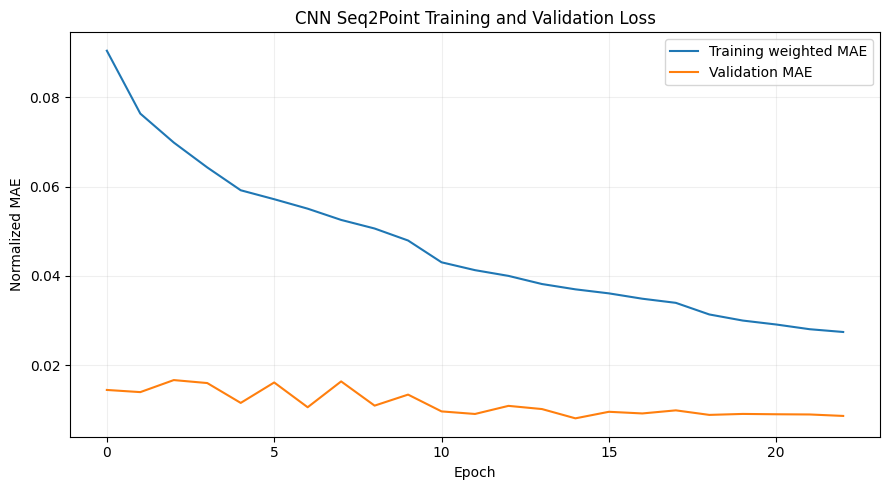

In [65]:
# ============================================================
# TRAINING CURVES
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    cnn_history.history["loss"],
    label="Training weighted MAE"
)

plt.plot(
    cnn_history.history["val_loss"],
    label="Validation MAE"
)

plt.xlabel("Epoch")
plt.ylabel("Normalized MAE")
plt.title("CNN Seq2Point Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    CNN_OUTPUT_DIR / "training_curves.png",
    dpi=200
)

plt.show()

In [66]:
# ============================================================
# CNN PREDICTIONS
# ============================================================

def cnn_predict_power(model, X_scaled):

    predictions_scaled = model.predict(
        X_scaled,
        batch_size=CNN_BATCH_SIZE,
        verbose=1
    ).reshape(-1)

    predictions_watts = (
        predictions_scaled * CNN_TARGET_SCALE
    )

    return np.clip(
        predictions_watts,
        0,
        None
    )


train_predictions_cnn = cnn_predict_power(
    cnn_model,
    X_train_cnn_scaled
)

val_predictions_cnn = cnn_predict_power(
    cnn_model,
    X_val_cnn_scaled
)

test_predictions_cnn = cnn_predict_power(
    cnn_model,
    X_test_cnn_scaled
)

print("CNN predictions generated.")

938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
484/484 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
CNN predictions generated.


In [67]:
# ============================================================
# CNN EVALUATION
# ============================================================

def cnn_compute_metrics(y_true, y_pred):

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    true_active = (
        y_true > CNN_ACTIVE_THRESHOLD
    )

    predicted_active = (
        y_pred > CNN_ACTIVE_THRESHOLD
    )

    active_mae = (
        mean_absolute_error(
            y_true[true_active],
            y_pred[true_active]
        )
        if np.any(true_active)
        else np.nan
    )

    total_true = np.sum(y_true)

    sae = (
        abs(np.sum(y_pred) - total_true) / total_true
        if total_true > 0
        else np.nan
    )

    return {
        "MAE_W": mean_absolute_error(
            y_true,
            y_pred
        ),

        "RMSE_W": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred
            )
        ),

        "R2": r2_score(
            y_true,
            y_pred
        ),

        "F1": f1_score(
            true_active,
            predicted_active,
            zero_division=0
        ),

        "Precision": precision_score(
            true_active,
            predicted_active,
            zero_division=0
        ),

        "Recall": recall_score(
            true_active,
            predicted_active,
            zero_division=0
        ),

        "Active_MAE_W": active_mae,

        "SAE": sae
    }


cnn_test_metrics = cnn_compute_metrics(
    y_test_cnn,
    test_predictions_cnn
)

print("\n========== CNN TEST RESULTS ==========")

for metric, value in cnn_test_metrics.items():
    print(f"{metric}: {value:.4f}")


========== CNN TEST RESULTS ==========
MAE_W: 28.8164
RMSE_W: 203.2883
R2: -0.3088
F1: 0.2704
Precision: 0.1887
Recall: 0.4769
Active_MAE_W: 524.5040
SAE: 0.2588


In [68]:

# ============================================================
# BASELINE COMPARISON
# ============================================================

# Baseline 1: Always OFF
cnn_always_off = np.zeros_like(y_test_cnn)

# Baseline 2: Training-household hourly profile
cnn_training_hour_data = []

for house_id in CNN_TRAIN_HOUSES:

    df, _ = cnn_load_house_data(house_id)

    df["hour"] = df["timestamp"].dt.hour

    cnn_training_hour_data.append(
        df[["hour", "target"]].dropna()
    )

    del df
    gc.collect()


cnn_hour_profile = (
    pd.concat(
        cnn_training_hour_data,
        ignore_index=True
    )
    .groupby("hour")["target"]
    .mean()
    .reindex(range(24), fill_value=0)
)

# Test timestamps
cnn_test_hours = pd.DatetimeIndex(test_times_cnn).hour

cnn_hourly_baseline = (
    cnn_hour_profile
    .reindex(cnn_test_hours)
    .to_numpy(dtype=float)
)

# ------------------------------------------------------------
# BUILD COMPARISON
# ------------------------------------------------------------

cnn_comparison_results = {}

# CNN Seq2Point
cnn_comparison_results["CNN Seq2Point"] = cnn_compute_metrics(
    y_test_cnn,
    test_predictions_cnn
)

# Original Random Forest
# Predict on the SAME test windows as the CNN.
if "best_model_v2" in globals():

    # CNN inputs are normalized.
    # Convert them back to raw aggregate power (Watts).
    X_test_rf_comparison = (
        X_test_cnn.squeeze(axis=-1) * CNN_AGGREGATE_SCALE
    )

    rf_predictions_same_windows = best_model_v2.predict(
        X_test_rf_comparison
    )

    cnn_comparison_results["Original Random Forest"] = (
        cnn_compute_metrics(
            y_test_cnn,
            rf_predictions_same_windows
        )
    )

    print("Random Forest evaluated on CNN test windows.")

else:
    print(
        "Original Random Forest model not found. "
        "Skipping RF comparison."
    )

# Always OFF
cnn_comparison_results["Always OFF"] = cnn_compute_metrics(
    y_test_cnn,
    cnn_always_off
)

# Hourly Profile
cnn_comparison_results["Hourly Profile"] = cnn_compute_metrics(
    y_test_cnn,
    cnn_hourly_baseline
)

# ------------------------------------------------------------
# DISPLAY AND SAVE RESULTS
# ------------------------------------------------------------

cnn_comparison = pd.DataFrame(
    cnn_comparison_results
).T

display(cnn_comparison.round(4))

cnn_comparison.to_csv(
    CNN_OUTPUT_DIR / "model_comparison.csv"
)

print(
    "\nComparison saved to:",
    CNN_OUTPUT_DIR / "model_comparison.csv"
)


Original Random Forest model not found. Skipping RF comparison.


,MAE_W,RMSE_W,R2,F1,Precision,Recall,Active_MAE_W,SAE
CNN Seq2Point,28.8164,203.2883,-0.3088,0.2704,0.1887,0.4769,524.5040,0.2588
Always OFF,18.5170,178.6579,-0.0109,0.0000,0.0000,0.0000,764.7581,1.0000
Hourly Profile,46.0332,177.9923,-0.0033,0.0864,0.0514,0.2705,723.9537,0.6407



Comparison saved to: /kaggle/working/cnn_seq2point_experiment/model_comparison.csv


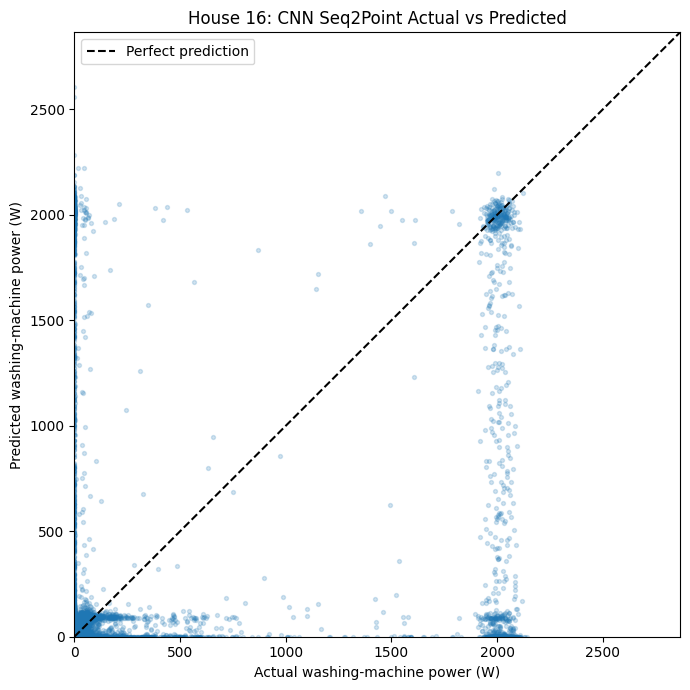

In [69]:
# ============================================================
# ACTUAL VS PREDICTED POWER
# ============================================================

cnn_max_value = max(
    float(np.max(y_test_cnn)),
    float(np.max(test_predictions_cnn)),
    1.0
) * 1.1

plt.figure(figsize=(7, 7))

plt.scatter(
    y_test_cnn,
    test_predictions_cnn,
    s=8,
    alpha=0.2
)

plt.plot(
    [0, cnn_max_value],
    [0, cnn_max_value],
    "k--",
    label="Perfect prediction"
)

plt.xlabel("Actual washing-machine power (W)")
plt.ylabel("Predicted washing-machine power (W)")

plt.title(
    "House 16: CNN Seq2Point Actual vs Predicted"
)

plt.xlim(0, cnn_max_value)
plt.ylim(0, cnn_max_value)

plt.legend()
plt.tight_layout()

plt.savefig(
    CNN_OUTPUT_DIR / "actual_vs_predicted.png",
    dpi=200
)

plt.show()

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


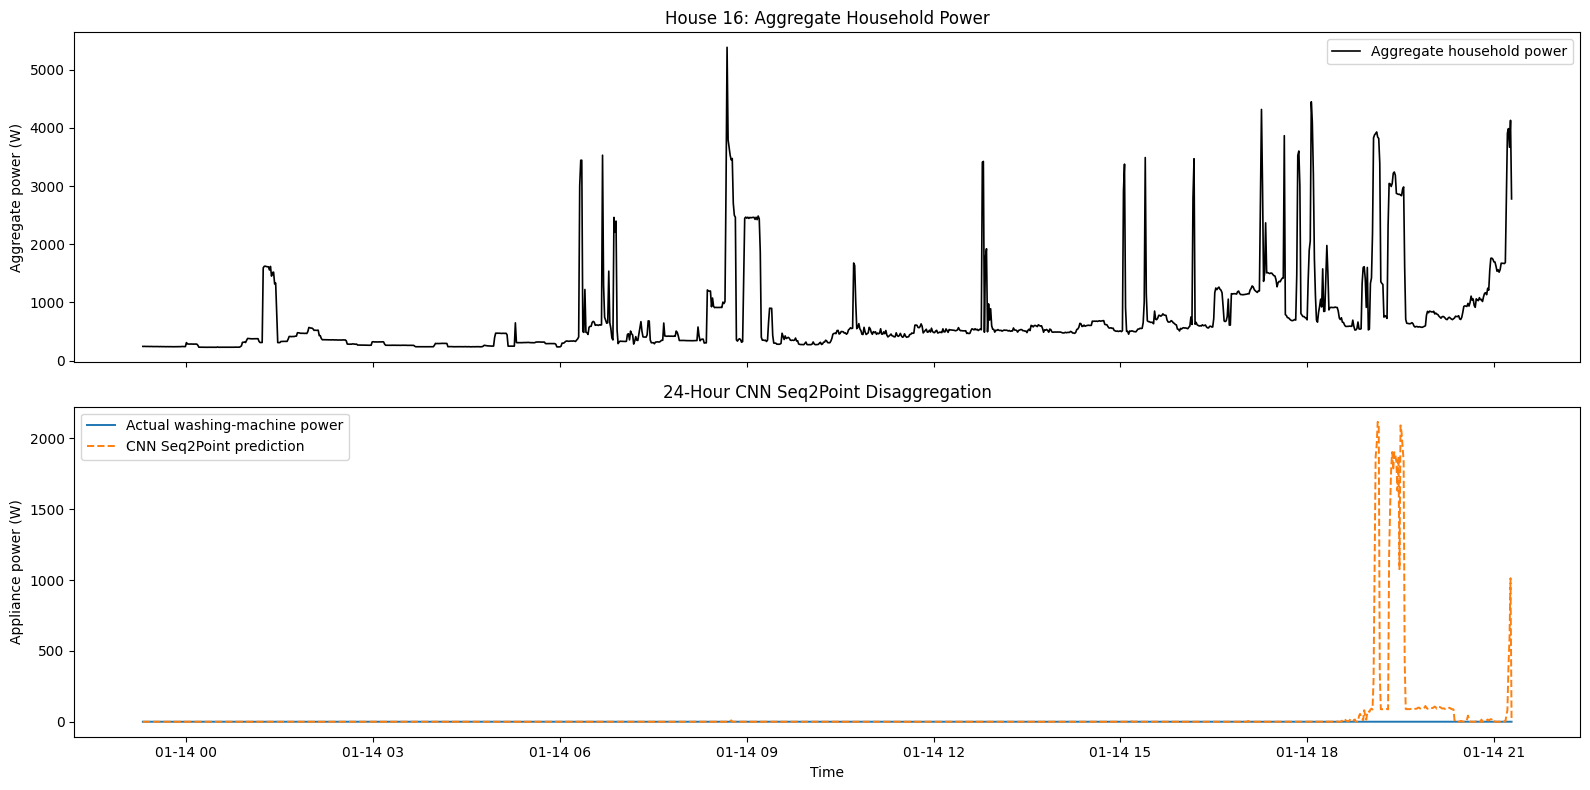

In [70]:
# ============================================================
# 24-HOUR DISAGGREGATION TRACE
# ============================================================

cnn_example_df, _ = cnn_load_house_data(16)

cnn_example_df = (
    cnn_example_df
    .iloc[5000:5000 + 24 * 60]
    .copy()
    .reset_index(drop=True)
)

cnn_example_valid = (
    cnn_example_df["aggregate"].notna()
    & cnn_example_df["target"].notna()
)

if cnn_example_valid.all() and len(cnn_example_df) >= CNN_WINDOW_SIZE:

    cnn_example_aggregate = (
        cnn_example_df["aggregate"]
        .to_numpy(dtype=np.float32)
    )

    cnn_example_windows = sliding_window_view(
        cnn_example_aggregate,
        CNN_WINDOW_SIZE
    )

    cnn_example_scaled = (
        cnn_example_windows / CNN_AGGREGATE_SCALE
    ).astype(np.float32)

    cnn_example_scaled = (
        cnn_example_scaled[..., np.newaxis]
    )

    cnn_example_predictions = cnn_predict_power(
        cnn_model,
        cnn_example_scaled
    )

    cnn_example_timestamps = (
        cnn_example_df["timestamp"].iloc[
            CNN_CENTER_INDEX:
            CNN_CENTER_INDEX + len(cnn_example_predictions)
        ].reset_index(drop=True)
    )

    cnn_example_actual = (
        cnn_example_df["target"].iloc[
            CNN_CENTER_INDEX:
            CNN_CENTER_INDEX + len(cnn_example_predictions)
        ].to_numpy()
    )

    cnn_example_aggregate_center = (
        cnn_example_df["aggregate"].iloc[
            CNN_CENTER_INDEX:
            CNN_CENTER_INDEX + len(cnn_example_predictions)
        ].to_numpy()
    )

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(16, 8),
        sharex=True
    )

    axes[0].plot(
        cnn_example_timestamps,
        cnn_example_aggregate_center,
        color="black",
        linewidth=1.2,
        label="Aggregate household power"
    )

    axes[0].set_ylabel("Aggregate power (W)")
    axes[0].legend()
    axes[0].set_title("House 16: Aggregate Household Power")

    axes[1].plot(
        cnn_example_timestamps,
        cnn_example_actual,
        label="Actual washing-machine power",
        linewidth=1.4
    )

    axes[1].plot(
        cnn_example_timestamps,
        cnn_example_predictions,
        label="CNN Seq2Point prediction",
        linestyle="--",
        linewidth=1.4
    )

    axes[1].set_ylabel("Appliance power (W)")
    axes[1].set_xlabel("Time")
    axes[1].set_title(
        "24-Hour CNN Seq2Point Disaggregation"
    )

    axes[1].legend()

    plt.tight_layout()

    plt.savefig(
        CNN_OUTPUT_DIR / "24_hour_disaggregation.png",
        dpi=200
    )

    plt.show()

else:
    print(
        "Selected 24-hour interval contains missing readings. "
        "Choose another continuous interval."
    )

In [71]:
# ============================================================
# CNN FAILURE CASE ANALYSIS
# ============================================================

cnn_error_df = pd.DataFrame({

    "timestamp": test_times_cnn,

    "actual_power": y_test_cnn,

    "predicted_power": test_predictions_cnn
})

cnn_error_df["absolute_error"] = np.abs(
    cnn_error_df["actual_power"]
    - cnn_error_df["predicted_power"]
)

cnn_error_df["actual_active"] = (
    cnn_error_df["actual_power"]
    > CNN_ACTIVE_THRESHOLD
)

cnn_error_df["predicted_active"] = (
    cnn_error_df["predicted_power"]
    > CNN_ACTIVE_THRESHOLD
)

cnn_error_df["failure_type"] = "Other"

cnn_error_df.loc[
    cnn_error_df["actual_active"]
    & ~cnn_error_df["predicted_active"],
    "failure_type"
] = "Missed appliance activity"

cnn_error_df.loc[
    ~cnn_error_df["actual_active"]
    & cnn_error_df["predicted_active"],
    "failure_type"
] = "False appliance activation"

cnn_error_df.loc[
    cnn_error_df["actual_active"]
    & cnn_error_df["predicted_active"]
    & (cnn_error_df["absolute_error"] > 100),
    "failure_type"
] = "Large error during active period"

print("Failure category counts:")

display(
    cnn_error_df["failure_type"]
    .value_counts()
    .to_frame("Number of samples")
)

print("\nLargest prediction errors:")

display(
    cnn_error_df
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(20)
)

cnn_error_df.to_csv(
    CNN_OUTPUT_DIR / "failure_analysis.csv",
    index=False
)

Failure category counts:


,Number of samples
failure_type,
Other,115841
False appliance activation,5980
Missed appliance activity,1526
Large error during active period,515



Largest prediction errors:


,timestamp,actual_power,predicted_power,absolute_error,actual_active,predicted_active,failure_type
27113,2014-05-22 23:28:00,0.000000,2604.845215,2604.845215,False,True,False appliance activation
27112,2014-05-22 23:23:00,0.000000,2559.439697,2559.439697,False,True,False appliance activation
13658,2014-04-05 07:21:00,0.000000,2284.789062,2284.789062,False,True,False appliance activation
11065,2014-03-26 19:42:00,15.625000,2222.050293,2206.425293,False,True,False appliance activation
59388,2014-10-12 15:49:00,0.000000,2189.994141,2189.994141,False,True,False appliance activation
4713,2014-03-02 15:05:00,0.000000,2186.661133,2186.661133,False,True,False appliance activation
22816,2014-05-07 19:14:00,45.900002,2219.993408,2174.093506,False,True,False appliance activation
96953,2015-03-09 21:24:00,0.000000,2156.277832,2156.277832,False,True,False appliance activation
40157,2014-07-10 04:39:00,2139.699951,0.008300,2139.691650,True,False,Missed appliance activity
27071,2014-05-22 19:58:00,0.000000,2136.423584,2136.423584,False,True,False appliance activation


In [72]:
# ============================================================
# SAVE CNN EXPERIMENT ARTIFACTS
# ============================================================

cnn_final_model_path = (
    CNN_OUTPUT_DIR / "final_seq2point_cnn.keras"
)

cnn_model.save(cnn_final_model_path)

# Save training history.
cnn_history_df = pd.DataFrame(
    cnn_history.history
)

cnn_history_df.to_csv(
    CNN_OUTPUT_DIR / "training_history.csv",
    index=False
)

# Save predictions for reproducibility.
cnn_predictions_df = pd.DataFrame({

    "timestamp": test_times_cnn,

    "actual_power": y_test_cnn,

    "predicted_power": test_predictions_cnn
})

cnn_predictions_df.to_csv(
    CNN_OUTPUT_DIR / "test_predictions.csv",
    index=False
)

cnn_summary = {

    "experiment": "CNN-based Seq2Point NILM",

    "architecture": "1D CNN",

    "window_size": CNN_WINDOW_SIZE,

    "center_index": CNN_CENTER_INDEX,

    "training_houses": CNN_TRAIN_HOUSES,

    "validation_houses": CNN_VAL_HOUSES,

    "test_houses": CNN_TEST_HOUSES,

    "training_stride_minutes": CNN_TRAIN_STRIDE,

    "evaluation_stride_minutes": CNN_EVAL_STRIDE,

    "batch_size": CNN_BATCH_SIZE,

    "maximum_epochs": CNN_EPOCHS,

    "actual_epochs": len(cnn_history.history["loss"]),

    "training_samples": int(len(y_train_cnn)),

    "validation_samples": int(len(y_val_cnn)),

    "test_samples": int(len(y_test_cnn)),

    "active_threshold_watts": CNN_ACTIVE_THRESHOLD,

    "sample_weighting": {
        "inactive": 1.0,
        "active_above_50W": 8.0,
        "active_above_1000W": 12.0,
        "normalized_to_mean_one": True
    },

    "training_time_seconds": float(cnn_training_time),

    "test_metrics": {
        key: (
            float(value)
            if np.isfinite(value)
            else None
        )
        for key, value in cnn_test_metrics.items()
    }
}

with open(
    CNN_OUTPUT_DIR / "experiment_summary.json",
    "w"
) as file:

    json.dump(
        cnn_summary,
        file,
        indent=4
    )

print("\n========== CNN EXPERIMENT COMPLETED ==========")

print("\nSaved files:")

for file_path in sorted(CNN_OUTPUT_DIR.iterdir()):
    print(file_path.name)

print("\nOutput directory:")
print(CNN_OUTPUT_DIR)


========== CNN EXPERIMENT COMPLETED ==========

Saved files:
24_hour_disaggregation.png
actual_vs_predicted.png
best_seq2point_cnn.keras
data_quality_report.csv
experiment_summary.json
failure_analysis.csv
final_seq2point_cnn.keras
model_comparison.csv
test_predictions.csv
training_curves.png
training_history.csv

Output directory:
/kaggle/working/cnn_seq2point_experiment


In [73]:
# Predict using the existing Random Forest on the CNN test windows.
# Both models now receive exactly the same test examples.

if "best_model_v2" in globals():

    rf_predictions_on_cnn_test = np.clip(
        best_model_v2.predict(X_test_cnn),
        0,
        None
    )

    rf_metrics_on_cnn_test = cnn_compute_metrics(
        y_test_cnn,
        rf_predictions_on_cnn_test
    )

else:
    rf_metrics_on_cnn_test = {
        key: np.nan for key in cnn_test_metrics
    }

cnn_comparison = pd.DataFrame({

    "CNN Seq2Point": cnn_compute_metrics(
        y_test_cnn,
        test_predictions_cnn
    ),

    "Random Forest (same test windows)": rf_metrics_on_cnn_test,

    "Always OFF": cnn_compute_metrics(
        y_test_cnn,
        cnn_always_off
    ),

    "Hourly Profile": cnn_compute_metrics(
        y_test_cnn,
        cnn_hourly_baseline
    )
}).T

display(cnn_comparison.round(4))

cnn_comparison.to_csv(
    CNN_OUTPUT_DIR / "model_comparison.csv"
)

,MAE_W,RMSE_W,R2,F1,Precision,Recall,Active_MAE_W,SAE
CNN Seq2Point,28.8164,203.2883,-0.3088,0.2704,0.1887,0.4769,524.5040,0.2588
Random Forest (same test windows),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Always OFF,18.5170,178.6579,-0.0109,0.0000,0.0000,0.0000,764.7581,1.0000
Hourly Profile,46.0332,177.9923,-0.0033,0.0864,0.0514,0.2705,723.9537,0.6407


ARRAY LENGTHS
Actual: 123862
Predicted: 123862
Timestamps: 123862

TIMESTAMP INFORMATION
First: 2014-01-10 11:58:00
Last: 2015-07-08 01:10:00
Sorted: True

POWER DISTRIBUTION
              Actual      Predicted
count  123862.000000  123862.000000
mean       18.516998      23.309673
std       177.610611     179.562241
min         0.000000       0.000000
50%         0.000000       0.000000
90%         0.000000       1.578827
95%         2.000000      77.112929
99%       324.105559     690.136459
max      2139.699951    2604.845215

ACTIVITY COUNTS
Actual active: 2917
Predicted active: 7371
True positives: 1391
False positives: 5980
False negatives: 1526

Actual active timestamp range:
2014-01-10 18:03:00
2015-07-04 19:02:00


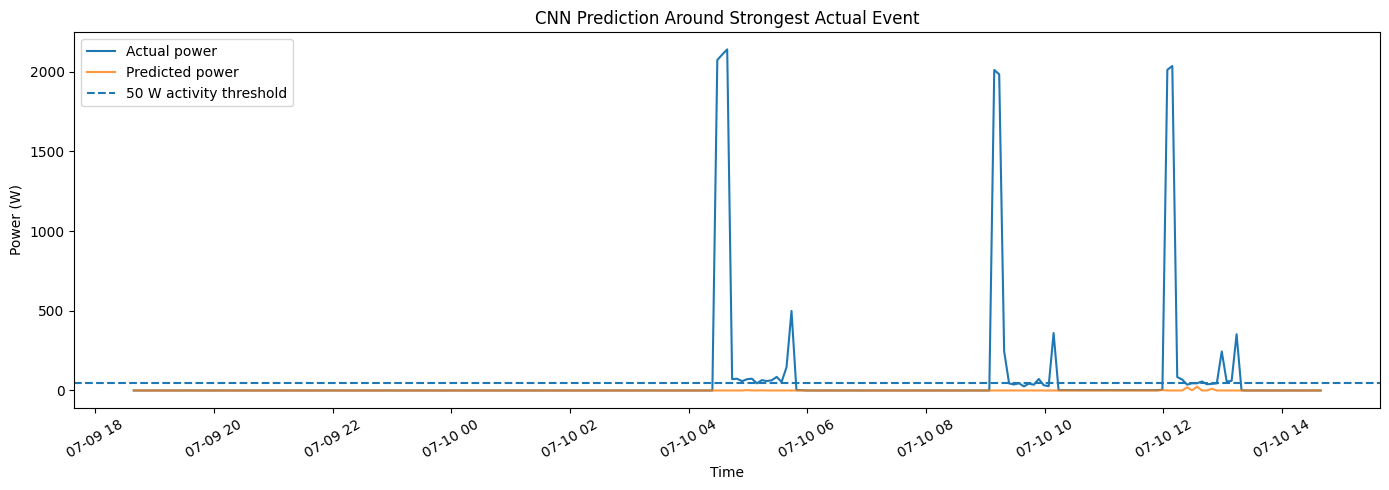

In [74]:

# ============================================================
# TEST SET ALIGNMENT AND PREDICTION DIAGNOSTICS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

actual = np.asarray(y_test_cnn).reshape(-1)
predicted = np.asarray(test_predictions_cnn).reshape(-1)
timestamps = pd.DatetimeIndex(test_times_cnn)

print("ARRAY LENGTHS")
print("Actual:", len(actual))
print("Predicted:", len(predicted))
print("Timestamps:", len(timestamps))

assert len(actual) == len(predicted) == len(timestamps), \
    "Actual, predicted and timestamp arrays are not aligned!"

print("\nTIMESTAMP INFORMATION")
print("First:", timestamps.min())
print("Last:", timestamps.max())
print("Sorted:", timestamps.is_monotonic_increasing)

print("\nPOWER DISTRIBUTION")
print(pd.DataFrame({
    "Actual": actual,
    "Predicted": predicted
}).describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

# Activity detection at 50 W
actual_active = actual > CNN_ACTIVE_THRESHOLD
predicted_active = predicted > CNN_ACTIVE_THRESHOLD

print("\nACTIVITY COUNTS")
print("Actual active:", actual_active.sum())
print("Predicted active:", predicted_active.sum())
print("True positives:", np.sum(actual_active & predicted_active))
print("False positives:", np.sum(~actual_active & predicted_active))
print("False negatives:", np.sum(actual_active & ~predicted_active))

# ------------------------------------------------------------
# PLOT ALL ACTUAL ACTIVE PERIODS
# ------------------------------------------------------------

active_indices = np.where(actual_active)[0]

print("\nActual active timestamp range:")

if len(active_indices):
    print(timestamps[active_indices].min())
    print(timestamps[active_indices].max())
else:
    print("No active samples found.")

# ------------------------------------------------------------
# PLOT AROUND THE STRONGEST ACTUAL WASHING-MACHINE EVENT
# ------------------------------------------------------------

if len(active_indices):

    strongest_idx = np.argmax(actual)

    start = max(0, strongest_idx - 120)
    end = min(len(actual), strongest_idx + 121)

    plt.figure(figsize=(14, 5))

    plt.plot(
        timestamps[start:end],
        actual[start:end],
        label="Actual power"
    )

    plt.plot(
        timestamps[start:end],
        predicted[start:end],
        label="Predicted power",
        alpha=0.8
    )

    plt.axhline(
        CNN_ACTIVE_THRESHOLD,
        linestyle="--",
        label="50 W activity threshold"
    )

    plt.title("CNN Prediction Around Strongest Actual Event")
    plt.xlabel("Time")
    plt.ylabel("Power (W)")
    plt.legend()
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


In [75]:

# ============================================================
# CHECK TEMPORAL GAPS IN CNN TEST SAMPLES
# ============================================================

timestamp_diffs = pd.Series(
    pd.DatetimeIndex(test_times_cnn)
).diff().dropna()

print("TIMESTAMP GAP DISTRIBUTION")
print("=" * 45)

print(timestamp_diffs.describe())

print("\nGap counts:")

for minutes in [5, 10, 30, 60, 1440]:
    count = (
        timestamp_diffs <= pd.Timedelta(minutes=minutes)
    ).sum()

    print(
        f"Gaps <= {minutes:4d} minutes: "
        f"{count} ({count / len(timestamp_diffs) * 100:.2f}%)"
    )

print("\nLargest gaps:")
print(timestamp_diffs.nlargest(10))


TIMESTAMP GAP DISTRIBUTION
count                       123861
mean     0 days 00:06:19.156635260
std      0 days 02:44:27.922707709
min                0 days 00:05:00
25%                0 days 00:05:00
50%                0 days 00:05:00
75%                0 days 00:05:00
max               27 days 16:24:00
dtype: object

Gap counts:
Gaps <=    5 minutes: 123694 (99.87%)
Gaps <=   10 minutes: 123694 (99.87%)
Gaps <=   30 minutes: 123694 (99.87%)
Gaps <=   60 minutes: 123694 (99.87%)
Gaps <= 1440 minutes: 123848 (99.99%)

Largest gaps:
3829     27 days 16:24:00
41250    24 days 03:39:00
112129    8 days 17:35:00
118322    7 days 14:23:00
64635     5 days 22:28:00
3922      5 days 22:27:00
68109     5 days 04:28:00
102588    4 days 10:39:00
100388    2 days 10:49:00
102213    1 days 14:09:00
dtype: timedelta64[ns]


In [76]:

# ============================================================
# CHECK CONSISTENCY OF TEST AND FAILURE ANALYSIS ARRAYS
# ============================================================

print("=" * 55)
print("TEST DATA CONSISTENCY CHECK")
print("=" * 55)

print("CNN test targets:", len(y_test_cnn))
print("CNN predictions:", len(test_predictions_cnn))
print("CNN timestamps:", len(test_times_cnn))

print("\nFailure analysis DataFrame:")

if "cnn_failure_df" in globals():
    print("Rows:", len(cnn_failure_df))
    print("Columns:", cnn_failure_df.columns.tolist())

elif "failure_df_cnn" in globals():
    print("Rows:", len(failure_df_cnn))
    print("Columns:", failure_df_cnn.columns.tolist())

else:
    print("Failure DataFrame variable not found.")

# Verify test arrays
assert len(y_test_cnn) == len(test_predictions_cnn)
assert len(y_test_cnn) == len(test_times_cnn)

# Recalculate activity counts
actual_active = np.asarray(y_test_cnn) > CNN_ACTIVE_THRESHOLD
predicted_active = (
    np.asarray(test_predictions_cnn) > CNN_ACTIVE_THRESHOLD
)

print("\nRecalculated test activity:")
print("Actual active:", actual_active.sum())
print("Predicted active:", predicted_active.sum())
print("True positives:", np.sum(actual_active & predicted_active))
print("False positives:", np.sum(~actual_active & predicted_active))
print("False negatives:", np.sum(actual_active & ~predicted_active))

print("\nExpected test samples:", len(y_test_cnn))


TEST DATA CONSISTENCY CHECK
CNN test targets: 123862
CNN predictions: 123862
CNN timestamps: 123862

Failure analysis DataFrame:
Failure DataFrame variable not found.

Recalculated test activity:
Actual active: 2917
Predicted active: 7371
True positives: 1391
False positives: 5980
False negatives: 1526

Expected test samples: 123862


In [77]:

# ============================================================
# FINAL FULL TEST-SET EVALUATION
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    f1_score,
    precision_score,
    recall_score
)

actual = np.asarray(y_test_cnn).reshape(-1)
predicted = np.asarray(test_predictions_cnn).reshape(-1)

threshold = CNN_ACTIVE_THRESHOLD

actual_active = actual > threshold
predicted_active = predicted > threshold

full_test_metrics = {
    "Samples": len(actual),
    "MAE_W": mean_absolute_error(actual, predicted),
    "RMSE_W": np.sqrt(mean_squared_error(actual, predicted)),
    "R2": r2_score(actual, predicted),
    "F1": f1_score(actual_active, predicted_active, zero_division=0),
    "Precision": precision_score(
        actual_active, predicted_active, zero_division=0
    ),
    "Recall": recall_score(
        actual_active, predicted_active, zero_division=0
    ),
    "Active_MAE_W": (
        mean_absolute_error(
            actual[actual_active],
            predicted[actual_active]
        )
        if actual_active.any() else np.nan
    ),
    "SAE": (
        abs(predicted.sum() - actual.sum()) / actual.sum()
        if actual.sum() > 0 else np.nan
    )
}

display(
    pd.DataFrame([full_test_metrics]).round(4)
)

pd.DataFrame([full_test_metrics]).to_csv(
    CNN_OUTPUT_DIR / "full_test_metrics.csv",
    index=False
)

print("Saved full test-set metrics.")


,Samples,MAE_W,RMSE_W,R2,F1,Precision,Recall,Active_MAE_W,SAE
0,123862,28.8164,203.2883,-0.3088,0.2704,0.1887,0.4769,524.504,0.2588


Saved full test-set metrics.
